# Enveda CASMI 2026 — Exploratory Data Analysis & Visualization

## 1. Imports & dependencies


In [2]:
from pathlib import Path
from collections import Counter
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
RANDOM_STATE = 45

## 2. Locate Dataset



In [3]:
PARTS_DIR = Path.cwd().parent.parent / "data" / "train_parts"

def find_train_files():
    paths = [PARTS_DIR / f"train{i}.csv" for i in range(1, 7)]
    if all(p.exists() for p in paths):
        return paths     
        
    try:
        paths = [next(Path.cwd().parent.parent.rglob(f"train{i}.csv")) for i in range(1, 7)]
        if all(p.exists() for p in paths):
            return paths
            
    except (StopIteration, PermissionError):
        pass
        
    return []



TRAIN_FILES = find_train_files()

if TRAIN_FILES:
    print("Found:")
    for p in TRAIN_FILES:
        print(" ", p.resolve())
else:
    print("Could not find files.")


Found:
  /home/manavtejani/Desktop/Dev/Kaggle/Chemistry/data/train_parts/train1.csv
  /home/manavtejani/Desktop/Dev/Kaggle/Chemistry/data/train_parts/train2.csv
  /home/manavtejani/Desktop/Dev/Kaggle/Chemistry/data/train_parts/train3.csv
  /home/manavtejani/Desktop/Dev/Kaggle/Chemistry/data/train_parts/train4.csv
  /home/manavtejani/Desktop/Dev/Kaggle/Chemistry/data/train_parts/train5.csv
  /home/manavtejani/Desktop/Dev/Kaggle/Chemistry/data/train_parts/train6.csv


## 3. Configuration(Limit Setting)


In [4]:
CHUNK_SIZE = 25_000
PLOT_SAMPLE_PER_FILE = 20_000
MAX_CATEGORIES = 20

## 4. File sizes & Schema


In [5]:
if len(TRAIN_FILES) != 6:
    raise FileNotFoundError("Set TRAIN_FILES to all six CSV paths in Section 2")


schema = []
for path in TRAIN_FILES:
    cols = pd.read_csv(path, nrows=0).columns.tolist()
    schema.append({"file": path.name, "size_MB": round(path.stat().st_size / 1024**2, 2),"column_count": len(cols), "columns": cols})
    
    
    
    
    
display(pd.DataFrame(schema)[["file", "size_MB", "column_count"]])


,file,size_MB,column_count
0,train1.csv,3322.05,18
1,train2.csv,3319.87,18
2,train3.csv,3171.37,18
3,train4.csv,1514.93,18
4,train5.csv,402.96,18
5,train6.csv,461.00,18


## 5. Helper Safety functions


In [6]:
def safenum(series):
    return pd.to_numeric(series, errors="coerce")





def safearray(value):
    if value is None or (isinstance(value, float) and np.isnan(value)):
        return None
    
    if isinstance(value, (list, tuple, np.ndarray)):
        return list(value)
    
    if not isinstance(value, str):
        return None
    
    try:
        result = ast.literal_eval(value)
        return list(result) if isinstance(result, (list, tuple, np.ndarray)) else None
    
    except (ValueError, SyntaxError, TypeError, MemoryError):
        return None
    
    
    

def safelimit(series, max_categories=30):
    
    counts = series.fillna("Missing").astype(str).value_counts()

    if len(counts) > max_categories:
        top = counts.iloc[:max_categories - 1]
        other_count = counts.iloc[max_categories - 1:].sum()

        top.loc["Other"] = other_count
        counts = top

    return counts





def safemiss(df, title):
    pct = df.isna().mean().mul(100).sort_values()
    ax = pct.plot(kind="barh", figsize=(10, max(4, len(pct)*0.32)))
    
    ax.set_title(title)
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("Column")
    
    plt.tight_layout()
    plt.show()
    display(pct.rename("missing_percent").to_frame().round(2))

## 6. bounded plot sample


In [7]:
SAMPLE_COLUMNS = ["ingest_lib", "normalized_smiles", "inchikey", "inchikey14", "molecular_formula","ionization_mode", "instrument_type", "adduct", "adduct_orig", "precursor_mz","precursor_error_ppm", "num_peaks", "base_peak_intensity", "collision_energy_ev","collision_energy_orig", "collision_energy_orig_units"]

sample_parts = []


for path in TRAIN_FILES:
    header = pd.read_csv(path, nrows=0).columns.tolist()
    cols = [c for c in SAMPLE_COLUMNS if c in header]
    
    
    file_chunks = []
    for chunk in pd.read_csv(path, usecols=cols, chunksize=CHUNK_SIZE, low_memory=False):
        
        n = max(1, round(PLOT_SAMPLE_PER_FILE * len(chunk) / 500_000))
        
        if len(chunk) > n:
            chunk = chunk.sample(n, random_state=RANDOM_STATE)
            
        file_chunks.append(chunk)
        
    part = pd.concat(file_chunks, ignore_index=True) if file_chunks else pd.DataFrame(columns=cols)
    
    if len(part) > PLOT_SAMPLE_PER_FILE:
        part = part.sample(PLOT_SAMPLE_PER_FILE, random_state=RANDOM_STATE)
        
        
    part["source_file"] = path.name
    sample_parts.append(part)
    
    
    
    
sample_df = pd.concat(sample_parts, ignore_index=True)
for col in ["precursor_mz", "precursor_error_ppm", "num_peaks", "base_peak_intensity", "collision_energy_ev"]:
    if col in sample_df:
        sample_df[col] = safenum(sample_df[col])
        
        
print(f"Visualization sample: {len(sample_df):,} rows")
display(sample_df.head())

Visualization sample: 101,586 rows


,ingest_lib,normalized_smiles,inchikey,inchikey14,molecular_formula,ionization_mode,instrument_type,adduct,adduct_orig,precursor_mz,precursor_error_ppm,num_peaks,base_peak_intensity,collision_energy_ev,collision_energy_orig,collision_energy_orig_units,source_file
0,enveda-180,c1ccc2c(-c3nc(C4CCOC4)no3)cc(C3CC3)nc2c1,AKQQZAIXCVIIRA-UHFFFAOYSA-N,AKQQZAIXCVIIRA,C18H17N3O2,positive,timsTOF,[M+H]+,[M+H]+,308.1400,0.461373,1051,25267905.0,NaN,40,eV,train1.csv
1,drug_plus,NC(=O)NC1NC(=O)NC1=O,POJWUDADGALRAB-UHFFFAOYSA-N,POJWUDADGALRAB,C4H6N4O3,positive,NaN,[M+H]+,[M+H]+,159.0513,3.238591,200,NaN,NaN,NaN,unknown,train1.csv
2,enveda-180,O=C(NC1CCCCNC1=O)c1sc(-c2ccccc2)nc1-c1ccccc1,AIIUJKVRKSGSTE-UHFFFAOYSA-N,AIIUJKVRKSGSTE,C22H21N3O2S,positive,timsTOF,[2M+Na]+,[2M+Na]+,805.2611,0.499851,59,46153.0,NaN,60,eV,train1.csv
3,enveda-180,Cc1nc(NC(=O)NCc2nnc3n2CCC3)sc1Cc1ccc(F)cc1F,ABXZIESYEHUPCZ-UHFFFAOYSA-N,ABXZIESYEHUPCZ,C18H18F2N6OS,negative,timsTOF,[M-H]-,[M-H]-,403.1166,3.391837,26,12013.0,NaN,-60,eV,train1.csv
4,enveda-180,Cc1cc(C(=O)N2CCC(N)C2)nn1C(C)(C)C,AIVHPEJBXFFRQJ-UHFFFAOYSA-N,AIVHPEJBXFFRQJ,C13H22N4O,positive,timsTOF,[M+H]+,[M+H]+,251.1871,0.459333,80,77840.0,NaN,20,eV,train1.csv


## 7. Univariate numeric analysis

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
precursor_mz,101586.0,4.190375e+02,1.857199e+02,46.0651,138.0206,204.1062,308.1035,350.0912,4.902800e+02,7.755336e+02,9.791003e+02,2.157120e+03
precursor_error_ppm,101406.0,1.265813e+03,2.611616e+04,-2.0705,0.0300,0.1550,0.7742,1.5101,2.348500e+00,1.736300e+01,2.902371e+03,2.148206e+06
num_peaks,101586.0,1.564905e+02,4.464330e+02,1.0000,1.0000,3.0000,14.0000,42.0000,1.650000e+02,6.180000e+02,1.343300e+03,4.426100e+04
base_peak_intensity,55052.0,5.309127e+06,5.405967e+07,1.0000,100.0000,100.0000,19503.0000,176242.5000,1.246162e+06,1.652708e+07,7.354129e+07,6.355361e+09
collision_energy_ev,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


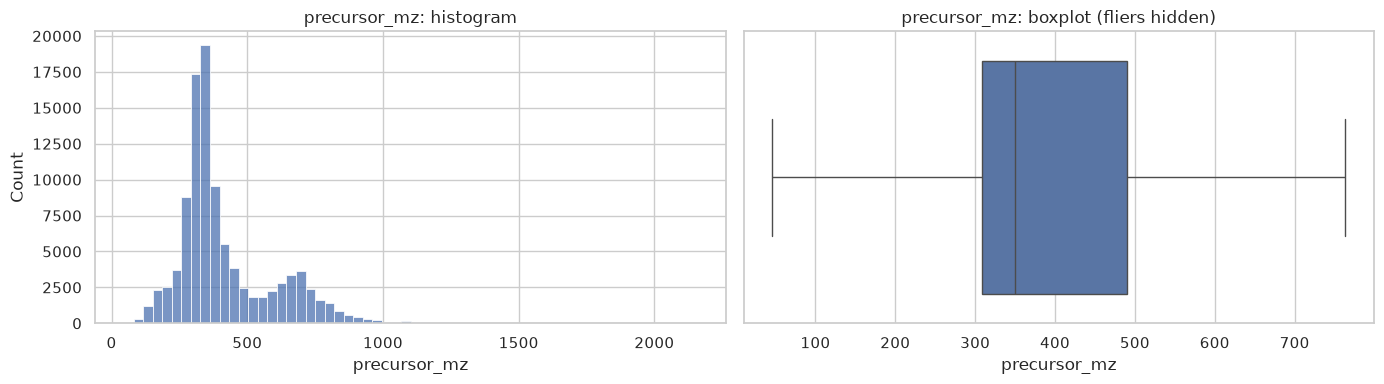

Compared mean/median, skew and tails for precursor_mz.


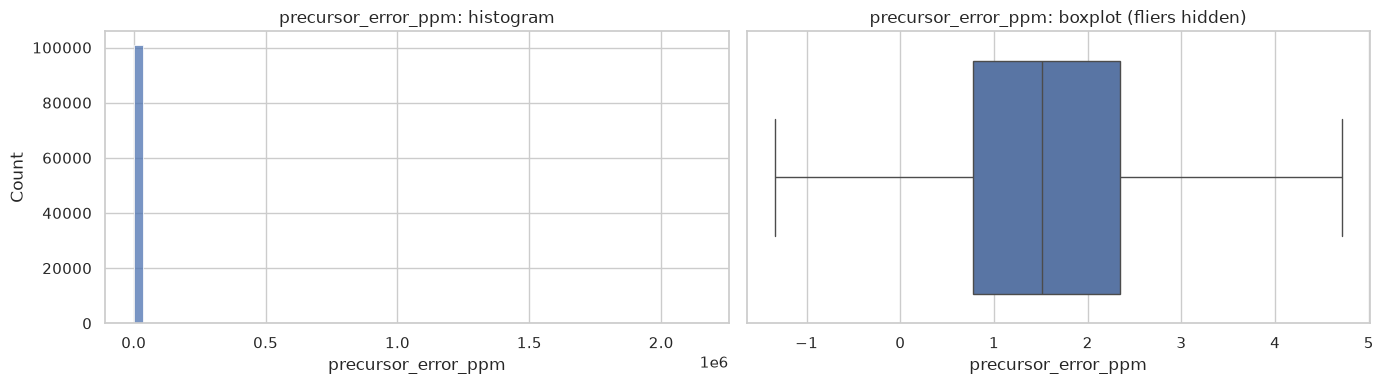

Compared mean/median, skew and tails for precursor_error_ppm.


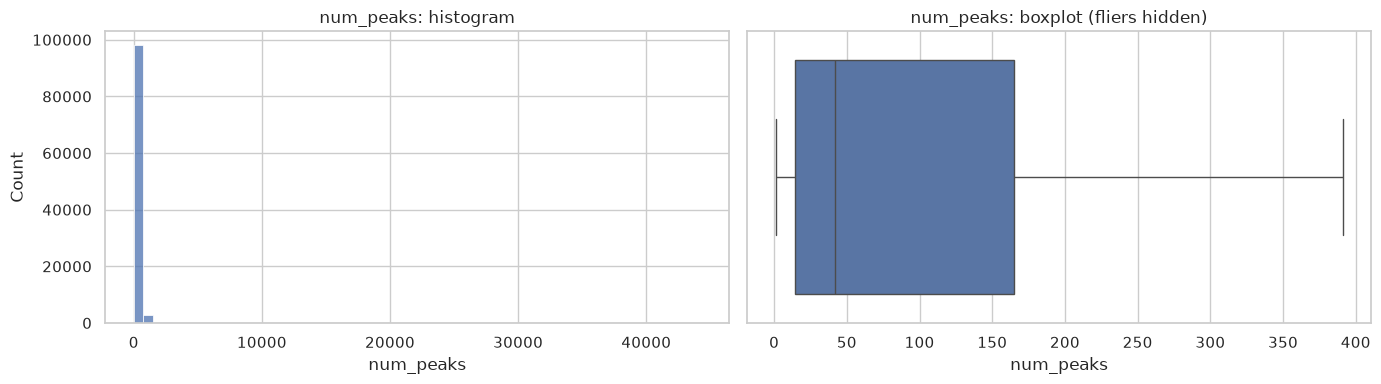

Compared mean/median, skew and tails for num_peaks.


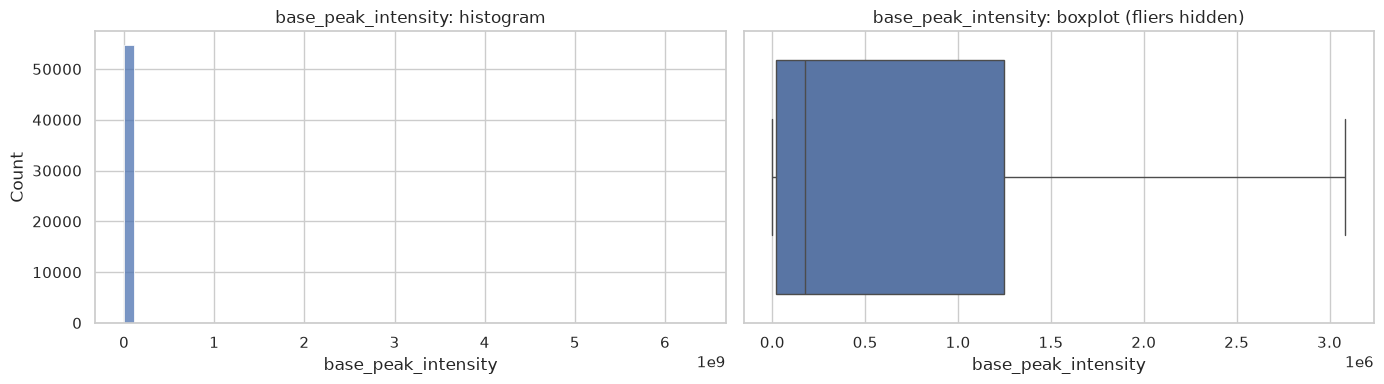

Compared mean/median, skew and tails for base_peak_intensity.


In [8]:
numcols = [c for c in ["precursor_mz", "precursor_error_ppm", "num_peaks","base_peak_intensity", "collision_energy_ev"] if c in sample_df]


display(sample_df[numcols].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T.round(4))


for col in numcols:
    values = safenum(sample_df[col]).replace([np.inf,-np.inf], np.nan).dropna()
    
    
    if values.empty: 
        continue
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    
    sns.histplot(values, bins=60, ax=axes[0], kde=(len(values) < 30_000))
    axes[0].set_title(f"{col}: histogram")
    axes[0].set_xlabel(col)
    
    
    sns.boxplot(x=values, ax=axes[1], showfliers=False)
    axes[1].set_title(f"{col}: boxplot (fliers hidden)")
    axes[1].set_xlabel(col)
    
    
    plt.tight_layout()
    plt.show()
    print(f"Compared mean/median, skew and tails for {col}.")

## 8. Univariate categorical analysis


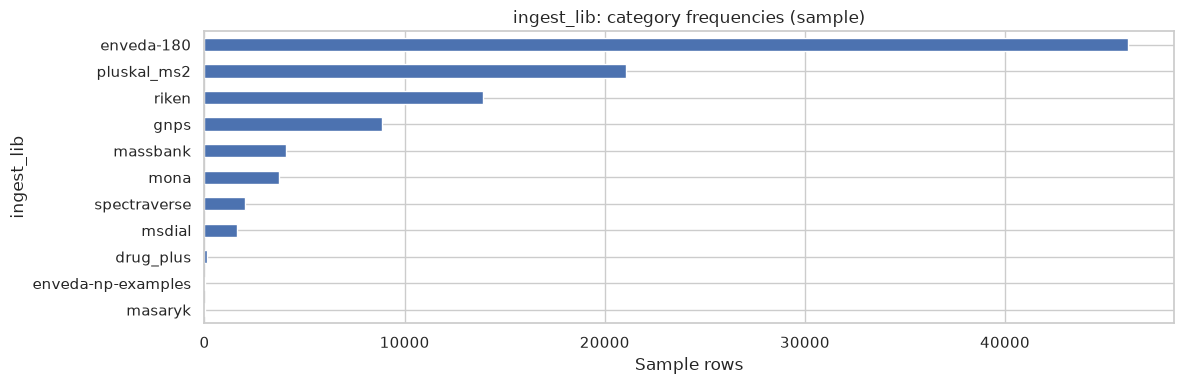

,sample_count
ingest_lib,
enveda-180,46138
pluskal_ms2,21085
riken,13905
gnps,8851
massbank,4064
mona,3709
spectraverse,2019
msdial,1647
drug_plus,105


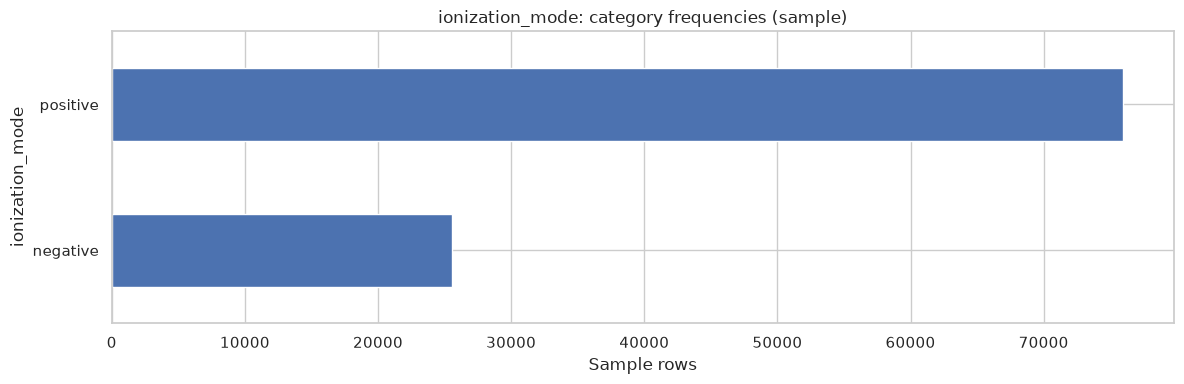

,sample_count
ionization_mode,
positive,75992
negative,25594


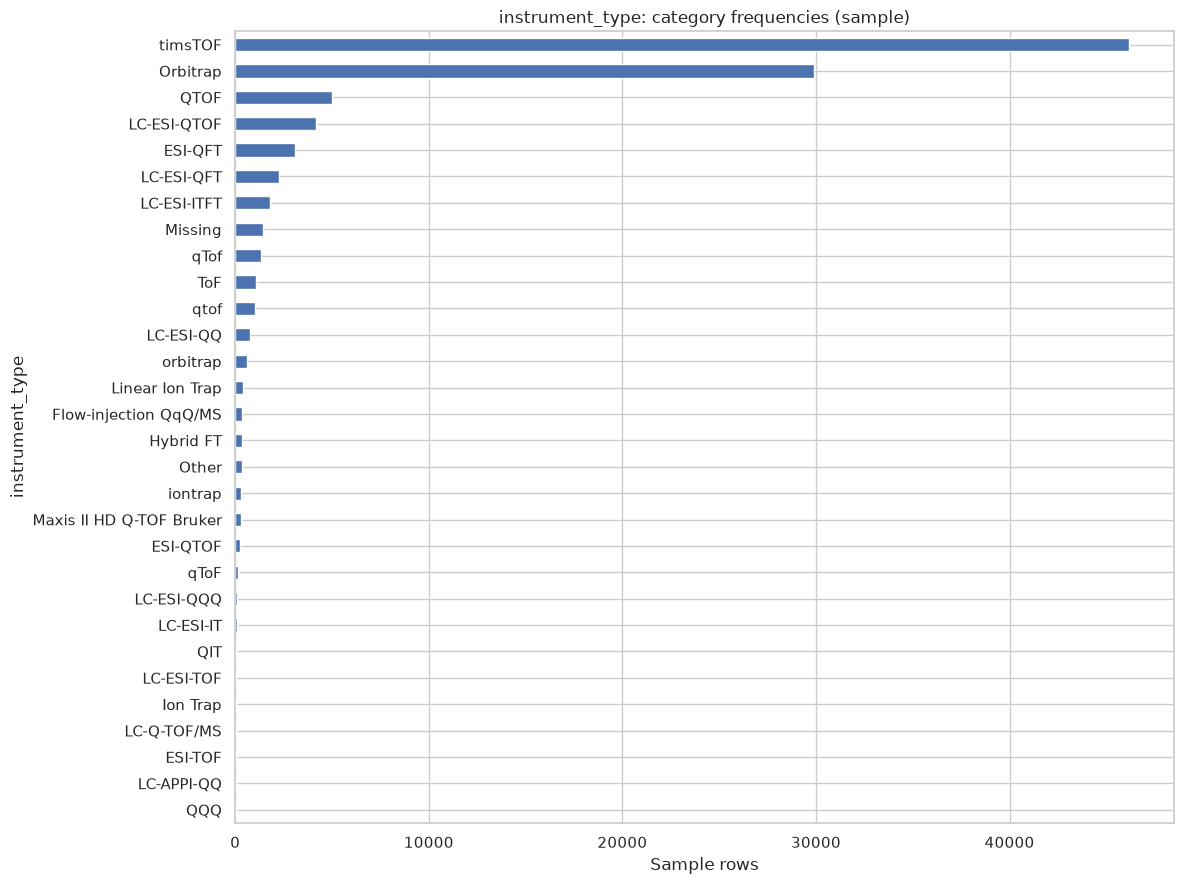

,sample_count
instrument_type,
timsTOF,46186
Orbitrap,29901
QTOF,5010
LC-ESI-QTOF,4151
ESI-QFT,3092
LC-ESI-QFT,2255
LC-ESI-ITFT,1801
Missing,1412
qTof,1350


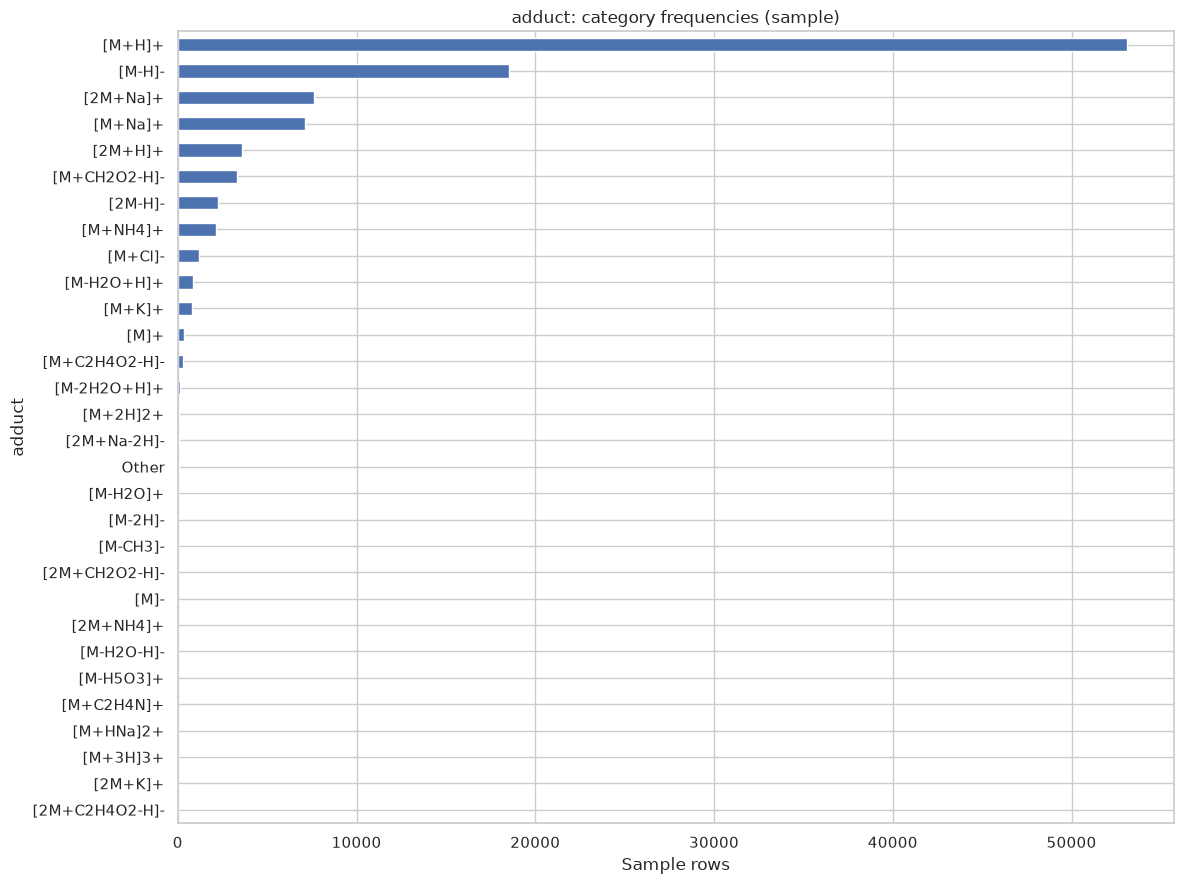

,sample_count
adduct,
[M+H]+,53077
[M-H]-,18538
[2M+Na]+,7596
[M+Na]+,7096
[2M+H]+,3621
[M+CH2O2-H]-,3308
[2M-H]-,2259
[M+NH4]+,2117
[M+Cl]-,1173


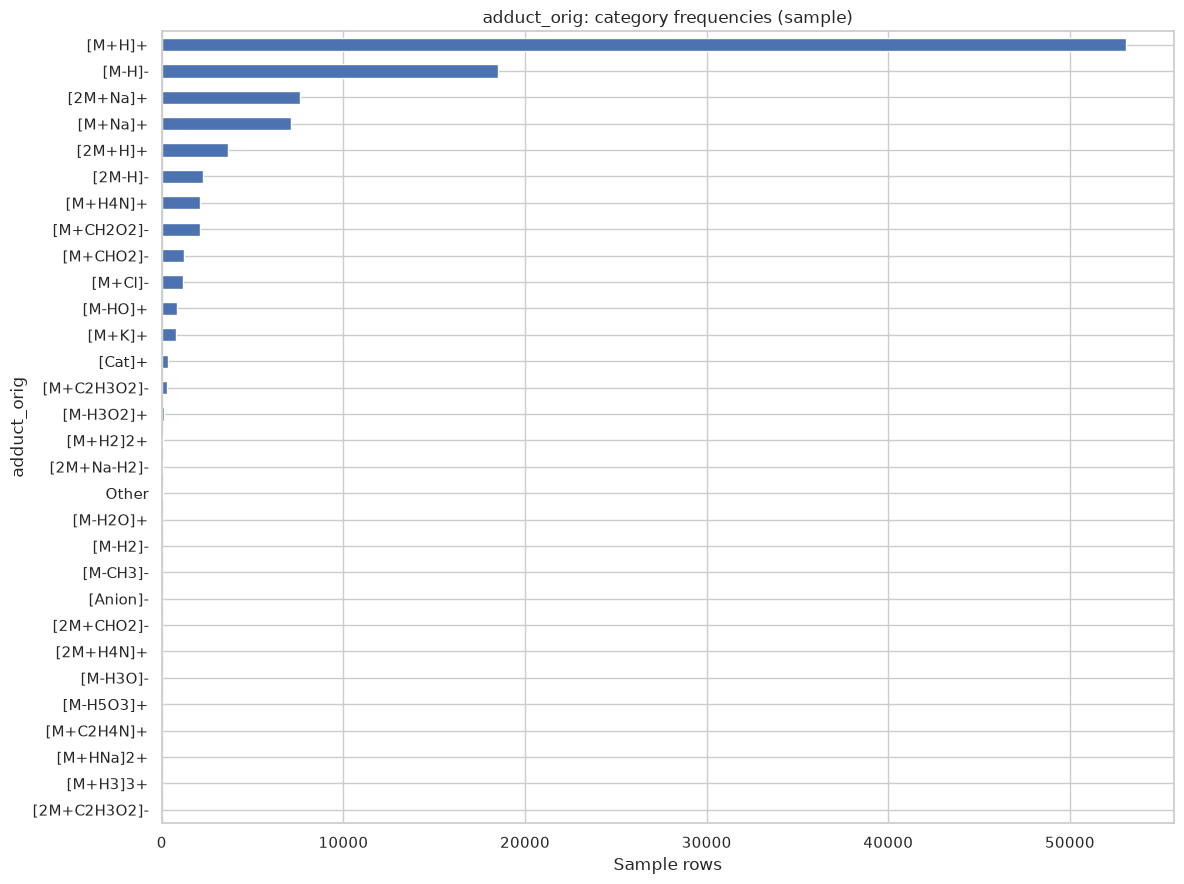

,sample_count
adduct_orig,
[M+H]+,53077
[M-H]-,18538
[2M+Na]+,7596
[M+Na]+,7096
[2M+H]+,3621
[2M-H]-,2259
[M+H4N]+,2117
[M+CH2O2]-,2096
[M+CHO2]-,1212


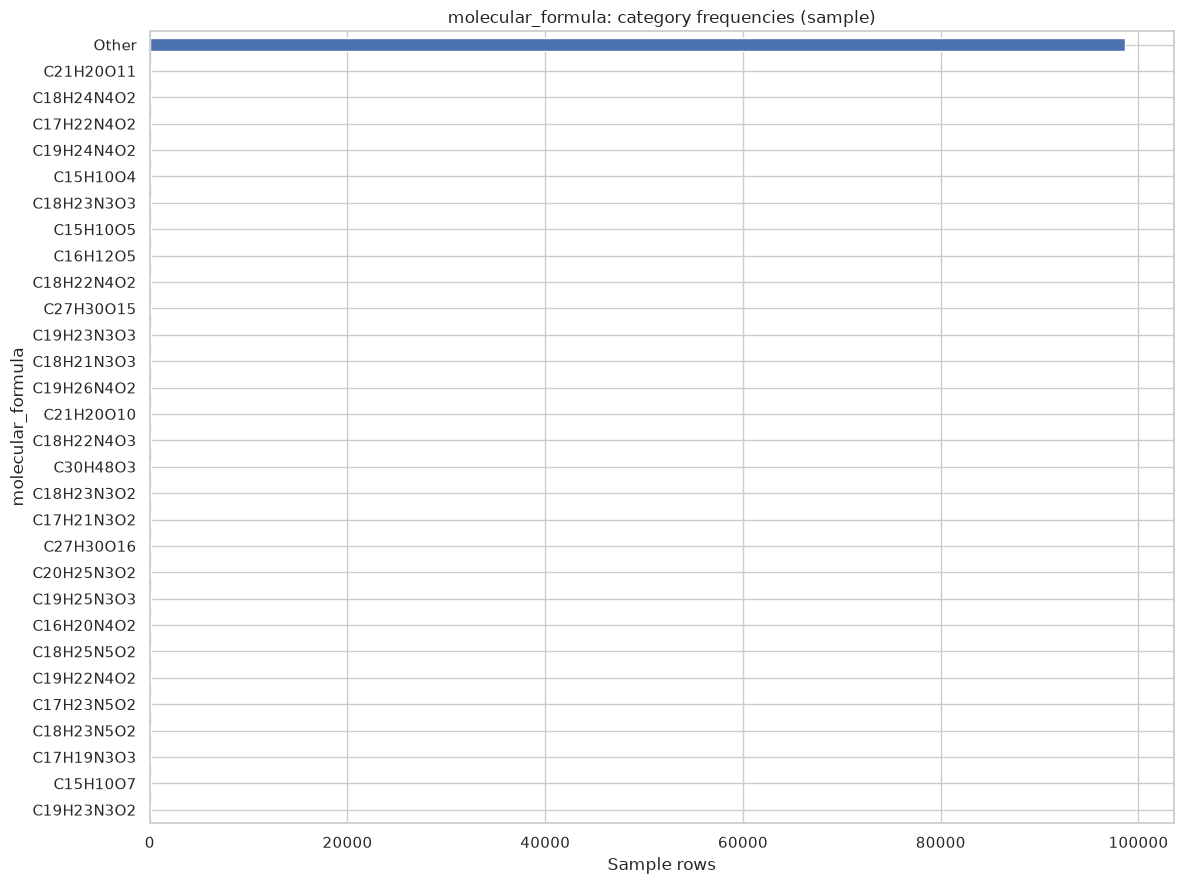

,sample_count
molecular_formula,
C21H20O11,137
C18H24N4O2,134
C17H22N4O2,128
C19H24N4O2,124
C15H10O4,119
C18H23N3O3,118
C15H10O5,117
C16H12O5,112
C18H22N4O2,107


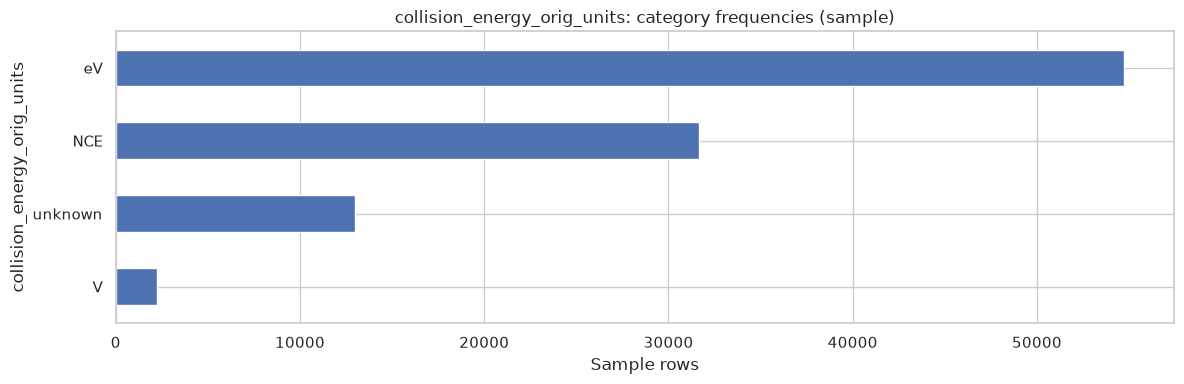

,sample_count
collision_energy_orig_units,
eV,54703
NCE,31656
unknown,13007
V,2220


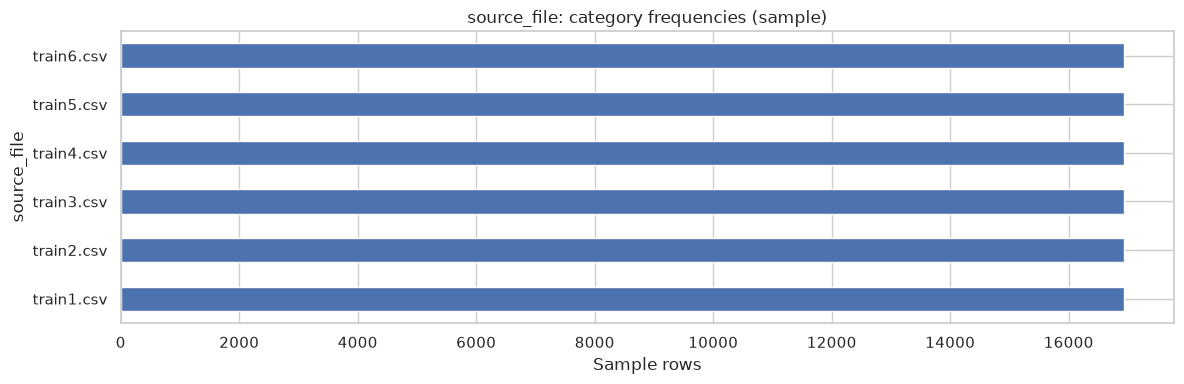

,sample_count
source_file,
train1.csv,16931
train2.csv,16931
train3.csv,16931
train4.csv,16931
train5.csv,16931
train6.csv,16931


In [9]:
catcols = [c for c in ["ingest_lib","ionization_mode","instrument_type","adduct","adduct_orig","molecular_formula","collision_energy_orig_units","source_file",]if c in sample_df.columns]

MAX_CATEGORIES = 30

for col in catcols:
    counts = safelimit(sample_df[col], MAX_CATEGORIES)

    fig, ax = plt.subplots(figsize=(12, max(4, min(9, 0.35 * len(counts)))))

    counts.sort_values().plot(kind="barh", ax=ax)

    ax.set_title(f"{col}: category frequencies (sample)")
    ax.set_xlabel("Sample rows")
    ax.set_ylabel(col)

    plt.tight_layout()
    plt.show()

    display(counts.rename("sample_count").to_frame())

## 9. Missing-data analysis


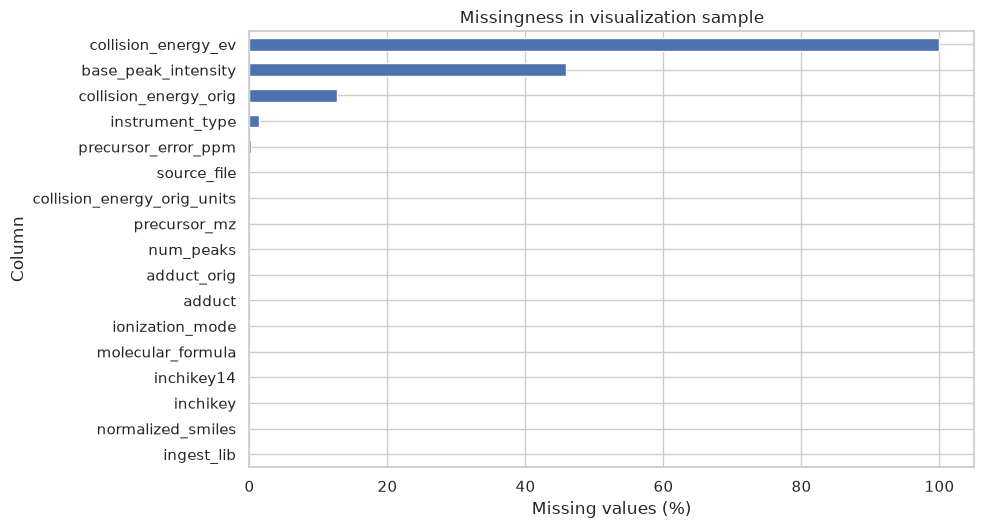

,missing_percent
ingest_lib,0.00
normalized_smiles,0.00
inchikey,0.00
inchikey14,0.00
molecular_formula,0.00
ionization_mode,0.00
adduct,0.00
adduct_orig,0.00
num_peaks,0.00
precursor_mz,0.00


In [10]:
safemiss(sample_df, "Missingness in visualization sample")

In [11]:
missrows = []

for path in TRAIN_FILES:
    
    header = pd.read_csv(path, nrows=0).columns.tolist()
    cols = [c for c in SAMPLE_COLUMNS if c in header]
    miss = Counter()
    total = 0
    
    
    for i in pd.read_csv(path, usecols=cols, chunksize=CHUNK_SIZE, low_memory=False):
        total += len(i)
        for c in cols: miss[c] += int(i[c].isna().sum())
        
        
    row = {"file": path.name, "rows_scanned": total}
    row.update({f"{c}_missing_pct": round(100*miss[c]/total, 3) if total else np.nan for c in cols})
    missrows.append(row)
    
    
missfile = pd.DataFrame(missrows).set_index("file")
display(missfile)

,rows_scanned,ingest_lib_missing_pct,normalized_smiles_missing_pct,inchikey_missing_pct,inchikey14_missing_pct,molecular_formula_missing_pct,ionization_mode_missing_pct,instrument_type_missing_pct,adduct_missing_pct,adduct_orig_missing_pct,precursor_mz_missing_pct,precursor_error_ppm_missing_pct,num_peaks_missing_pct,base_peak_intensity_missing_pct,collision_energy_ev_missing_pct,collision_energy_orig_missing_pct,collision_energy_orig_units_missing_pct
file,,,,,,,,,,,,,,,,,
train1.csv,423268,0.0,0.0,0.0,0.0,0.0,0.0,0.601,0.0,0.0,0.0,0.000,0.0,0.601,0.601,0.601,0.0
train2.csv,423268,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.000,0.0,0.000,0.000,0.000,0.0
train3.csv,423268,0.0,0.0,0.0,0.0,0.0,0.0,0.046,0.0,0.0,0.0,0.011,0.0,0.000,26.809,26.809,0.0
train4.csv,423268,0.0,0.0,0.0,0.0,0.0,0.0,3.427,0.0,0.0,0.0,0.949,0.0,74.478,33.707,31.878,0.0
train5.csv,423268,0.0,0.0,0.0,0.0,0.0,0.0,0.000,0.0,0.0,0.0,0.036,0.0,100.000,0.000,0.000,0.0
train6.csv,423268,0.0,0.0,0.0,0.0,0.0,0.0,4.124,0.0,0.0,0.0,0.017,0.0,99.720,18.606,16.424,0.0


## 10. Bar charts and pie charts


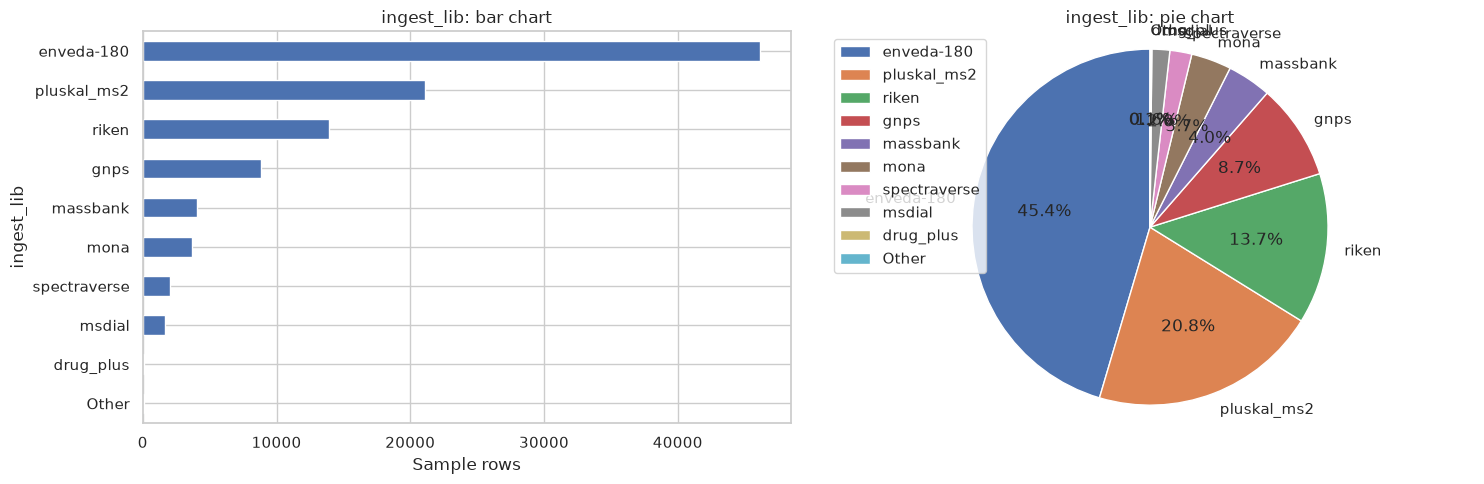

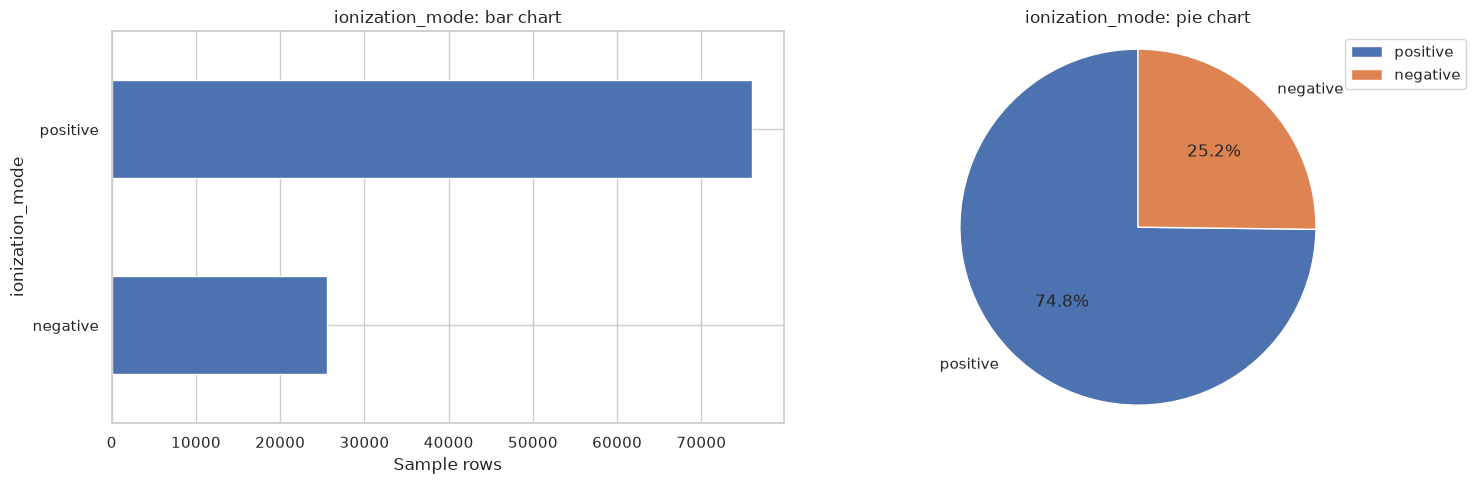

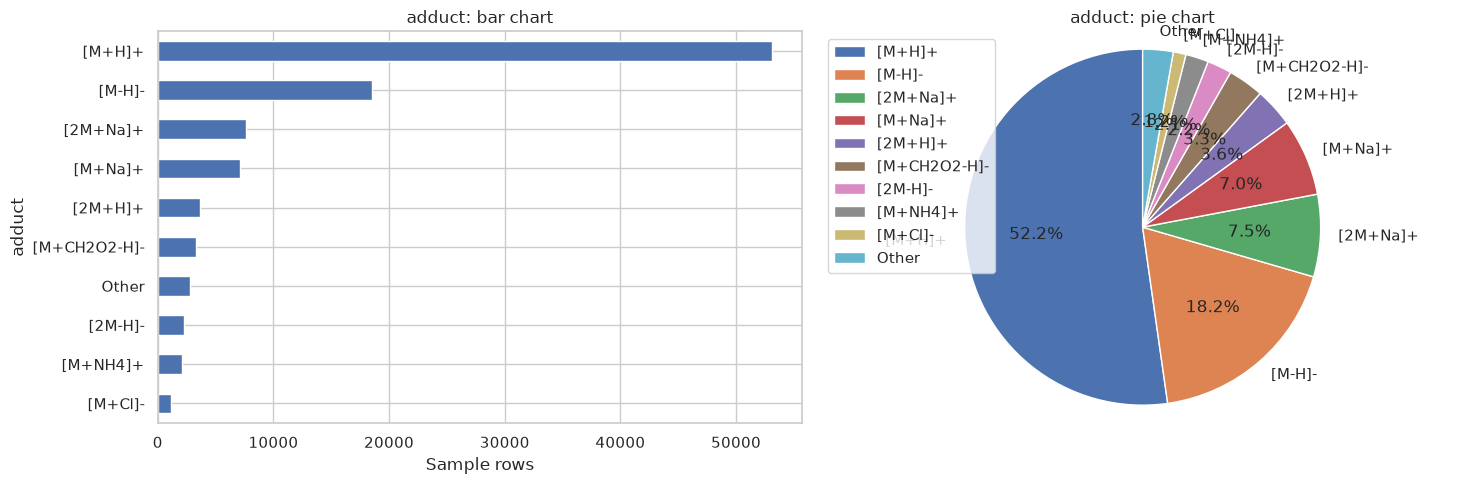

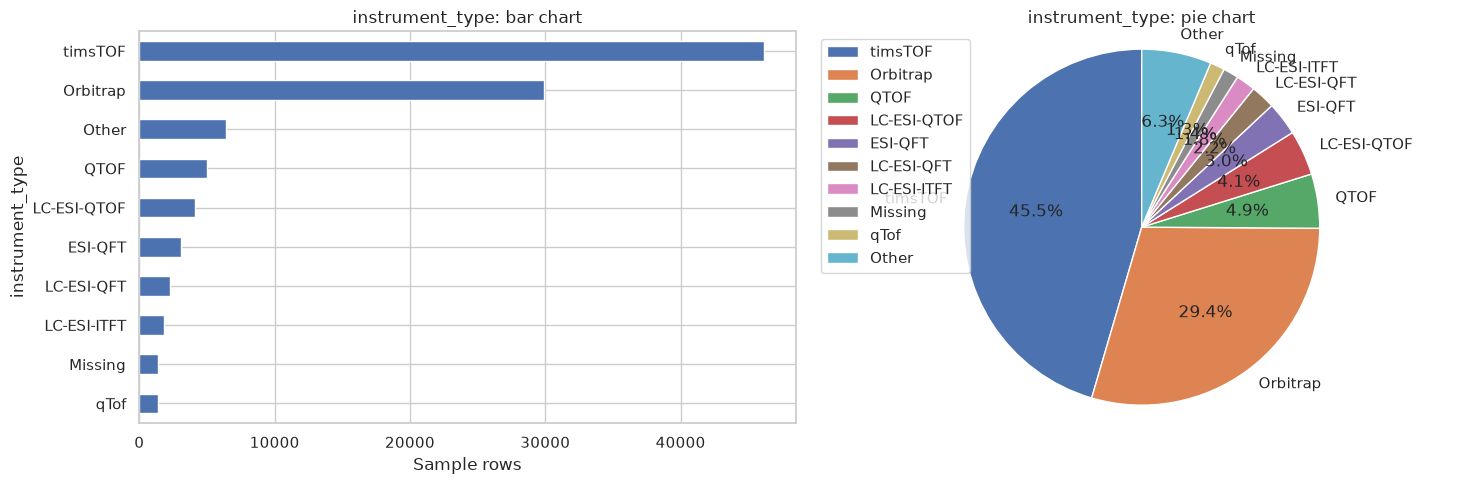

In [12]:
for col in [c for c in ["ingest_lib", "ionization_mode", "adduct", "instrument_type"] if c in sample_df]:
    
    counts = safelimit(sample_df[col], 10)
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    counts.sort_values().plot(kind="barh", ax=axes[0])
    
    axes[0].set_title(f"{col}: bar chart")
    axes[0].set_xlabel("Sample rows")
    axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
    axes[1].set_title(f"{col}: pie chart")
    axes[1].axis("equal")
    axes[1].legend()
    
    
    plt.tight_layout()
    plt.show()

## 11. Exact full-data category counts


Exact full-data counts — ingest_lib


,count
enveda-180,1153785
pluskal_ms2,527581
riken,347171
gnps,220849
massbank,101727
mona,92416
spectraverse,50933
msdial,40765
drug_plus,2545
enveda-np-examples,1184


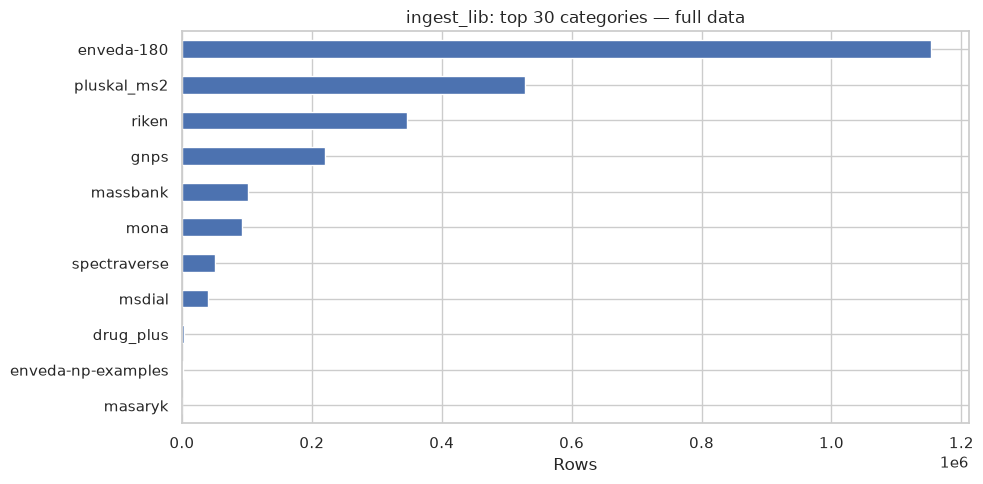

Exact full-data counts — ionization_mode


,count
positive,1899640
negative,639968


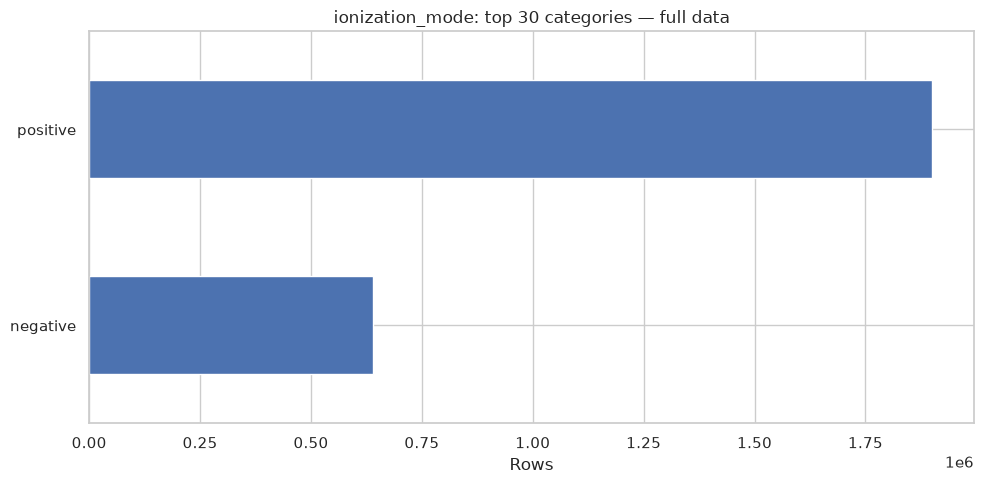

Exact full-data counts — adduct


,count
[M+H]+,1324585
[M-H]-,465688
[2M+Na]+,190033
[M+Na]+,178092
[2M+H]+,92041
[M+CH2O2-H]-,83188
[2M-H]-,56172
[M+NH4]+,53452
[M+Cl]-,27511
[M-H2O+H]+,21682


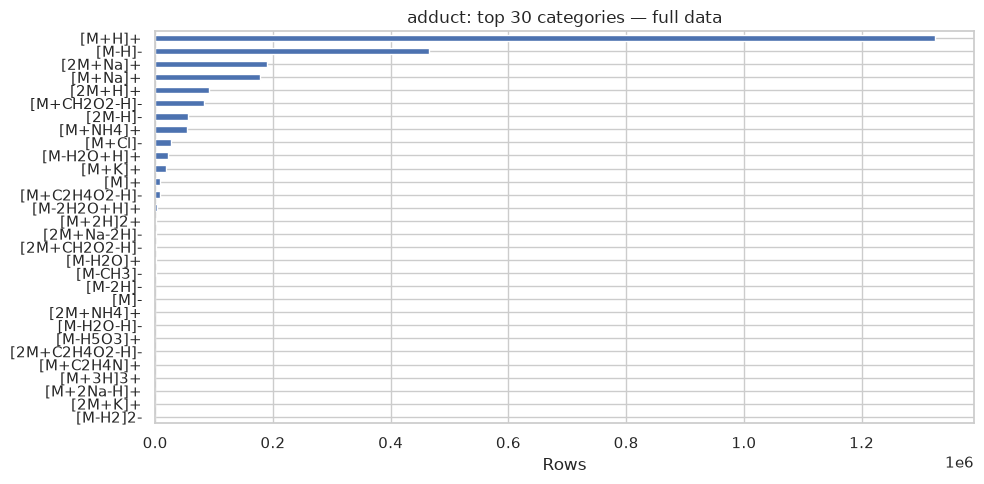

Exact full-data counts — instrument_type


,count
timsTOF,1154969
Orbitrap,745562
QTOF,125936
LC-ESI-QTOF,104482
ESI-QFT,77342
LC-ESI-QFT,55024
LC-ESI-ITFT,45109
<MISSING>,34698
qTof,33777
ToF,26535


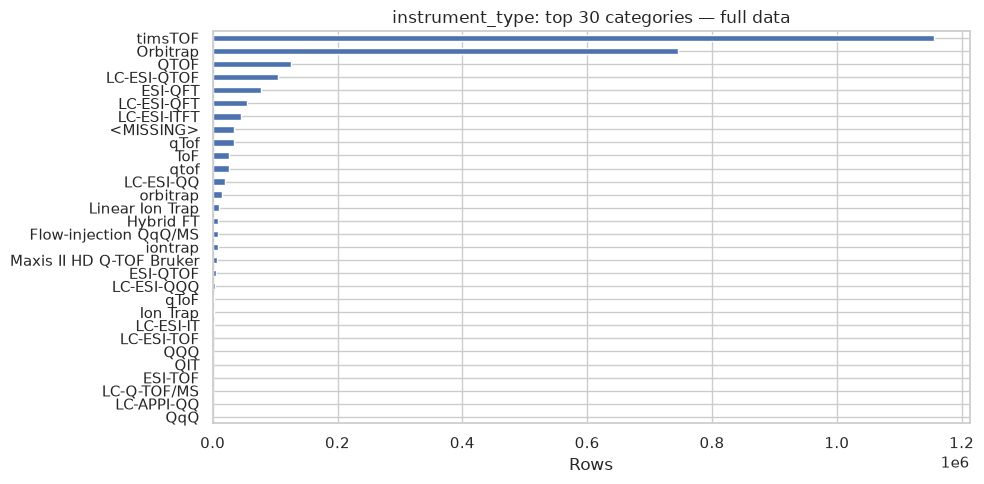

Exact full-data counts — collision_energy_orig_units


,count
eV,1368908
NCE,789066
unknown,325078
V,56556


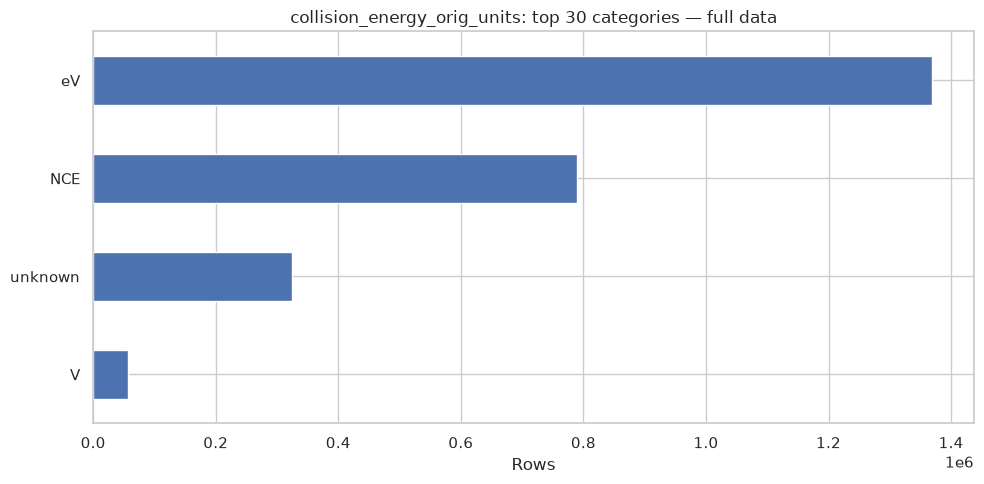

In [13]:
COUNT_COLUMNS = ["ingest_lib", "ionization_mode", "adduct", "instrument_type", "collision_energy_orig_units"]
full_counts = {c: Counter() for c in COUNT_COLUMNS}



for path in TRAIN_FILES:
    header = pd.read_csv(path, nrows=0).columns.tolist()
    cols = [c for c in COUNT_COLUMNS if c in header]
    
    
    for chunk in pd.read_csv(path, usecols=cols, chunksize=CHUNK_SIZE, low_memory=False):
        for col in cols:
            full_counts[col].update(chunk[col].fillna("<MISSING>").astype(str).value_counts().to_dict())
            
            
            
for col, counter in full_counts.items():
    if not counter: 
        continue
    
    counts = pd.Series(counter).sort_values(ascending=False)
    
    print(f"Exact full-data counts — {col}")
    display(counts.head(30).rename("count").to_frame())
    
    
    counts.head(MAX_CATEGORIES).sort_values().plot(kind="barh", figsize=(10,5))
    plt.title(f"{col}: top {MAX_CATEGORIES} categories — full data")
    plt.xlabel("Rows")
    plt.tight_layout()
    plt.show()

## 12. Multivariate analysis: library, adduct and ionization mode


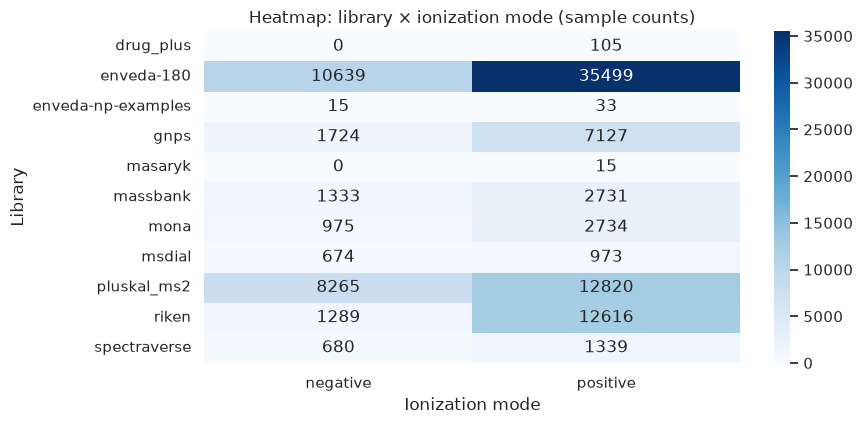

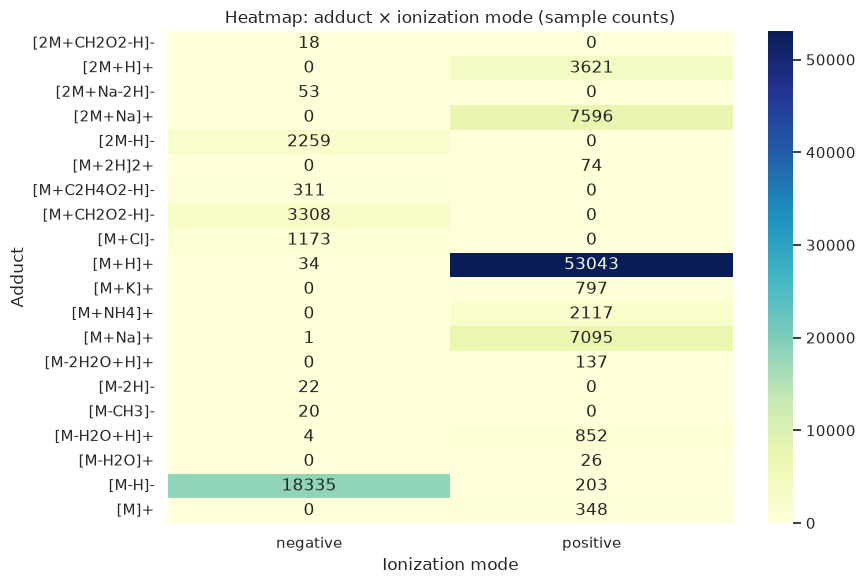

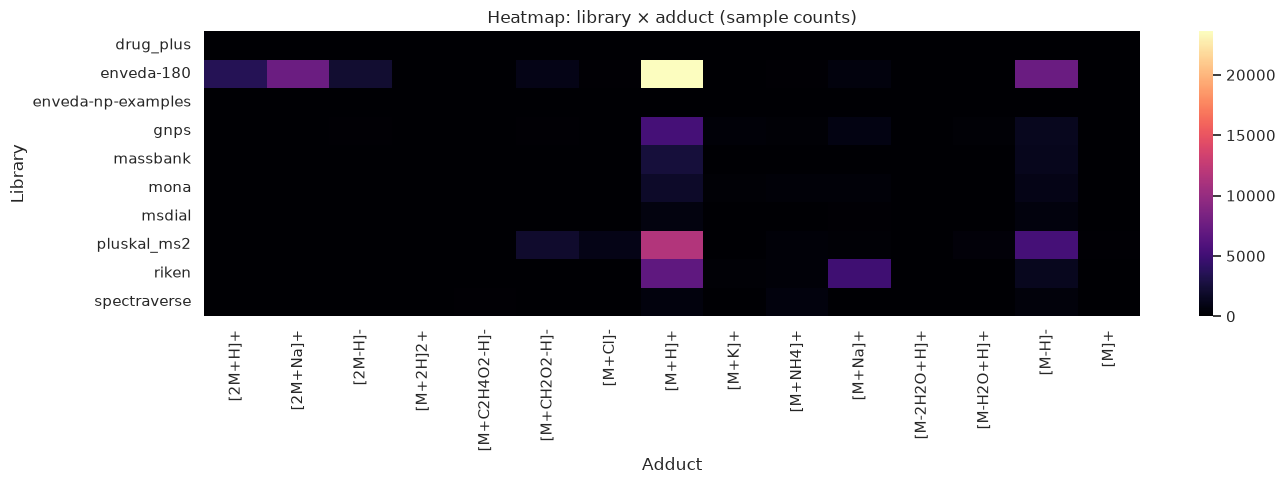

In [14]:
if {"ingest_lib","ionization_mode"}.issubset(sample_df.columns):
    ct = pd.crosstab(sample_df["ingest_lib"].fillna("<MISSING>"), sample_df["ionization_mode"].fillna("<MISSING>"))
    
    keep = sample_df["ingest_lib"].value_counts().head(15).index
    ct = ct.loc[ct.index.intersection(keep)]
    
    
    plt.figure(figsize=(9, max(4,.4*len(ct))))
    sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
    plt.title("Heatmap: library × ionization mode (sample counts)")
    plt.xlabel("Ionization mode")
    plt.ylabel("Library")
    
    plt.tight_layout()
    plt.show()
    
   
   
    
if {"adduct","ionization_mode"}.issubset(sample_df.columns):
    ct = pd.crosstab(sample_df["adduct"].fillna("<MISSING>"), sample_df["ionization_mode"].fillna("<MISSING>"))
    
    keep = sample_df["adduct"].value_counts().head(20).index
    ct = ct.loc[ct.index.intersection(keep)]
    
    
    plt.figure(figsize=(9,max(4,.3*len(ct))))
    sns.heatmap(ct, annot=True, fmt="d", cmap="YlGnBu")
    plt.title("Heatmap: adduct × ionization mode (sample counts)")
    plt.xlabel("Ionization mode")
    plt.ylabel("Adduct")
    
    plt.tight_layout()
    plt.show()
    
    
    
    
    
if {"ingest_lib","adduct"}.issubset(sample_df.columns):
    libs = sample_df["ingest_lib"].value_counts().head(10).index
    adducts = sample_df["adduct"].value_counts().head(15).index
    
    subset = sample_df[sample_df["ingest_lib"].isin(libs) & sample_df["adduct"].isin(adducts)]
    ct = pd.crosstab(subset["ingest_lib"], subset["adduct"])
    
    plt.figure(figsize=(14,max(5,.4*len(ct))))
    sns.heatmap(ct, cmap="magma")
    plt.title("Heatmap: library × adduct (sample counts)")
    plt.xlabel("Adduct")
    plt.ylabel("Library")
    
    plt.tight_layout()
    plt.show()

In [15]:
jcnt = Counter()
jcols = ["ingest_lib", "adduct", "ionization_mode"]


for path in TRAIN_FILES:
    header = pd.read_csv(path, nrows=0).columns.tolist()
    
    if not all(c in header for c in jcols):
        continue
    
    for chunk in pd.read_csv(path, usecols=jcols, chunksize=CHUNK_SIZE, low_memory=False):
        chunk = chunk.fillna("<MISSING>").astype(str)
        jcnt.update(map(tuple, chunk[jcols].itertuples(index=False, name=None)))
        
        
jdf = pd.DataFrame([(a,b,c,n) for (a,b,c),n in jcnt.items()],columns=["ingest_lib","adduct","ionization_mode","count"]).sort_values("count", ascending=False)
display(jdf.head(50))

,ingest_lib,adduct,ionization_mode,count
6,enveda-180,[M+H]+,positive,588507
242,pluskal_ms2,[M+H]+,positive,288671
8,enveda-180,[2M+Na]+,positive,188158
7,enveda-180,[M-H]-,negative,184747
252,riken,[M+H]+,positive,169287
21,gnps,[M+H]+,positive,134374
243,pluskal_ms2,[M-H]-,negative,133911
254,riken,[M+Na]+,positive,121677
11,enveda-180,[2M+H]+,positive,89487
67,massbank,[M+H]+,positive,64172


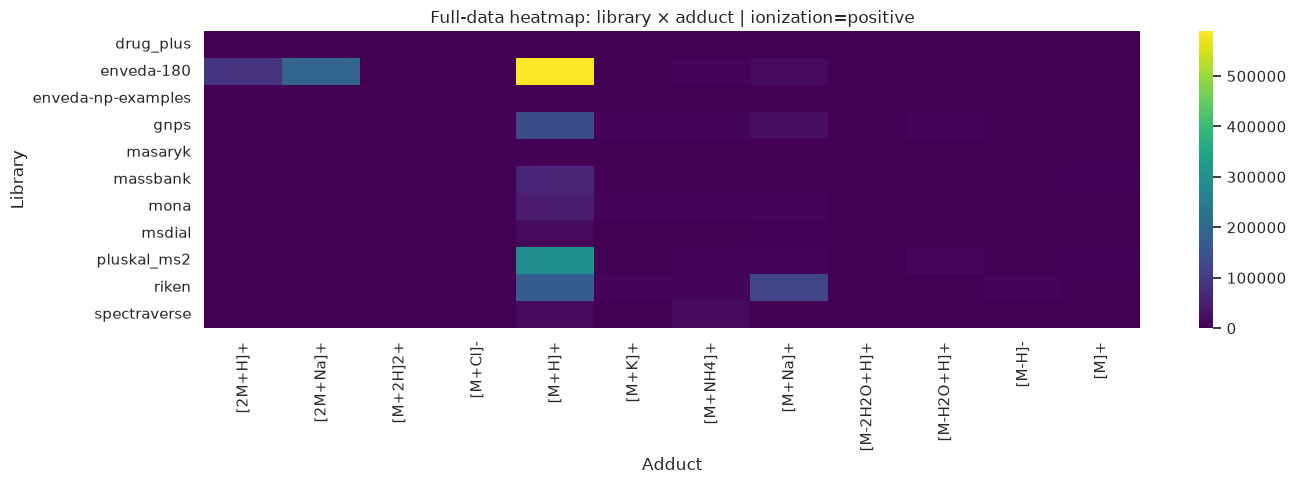

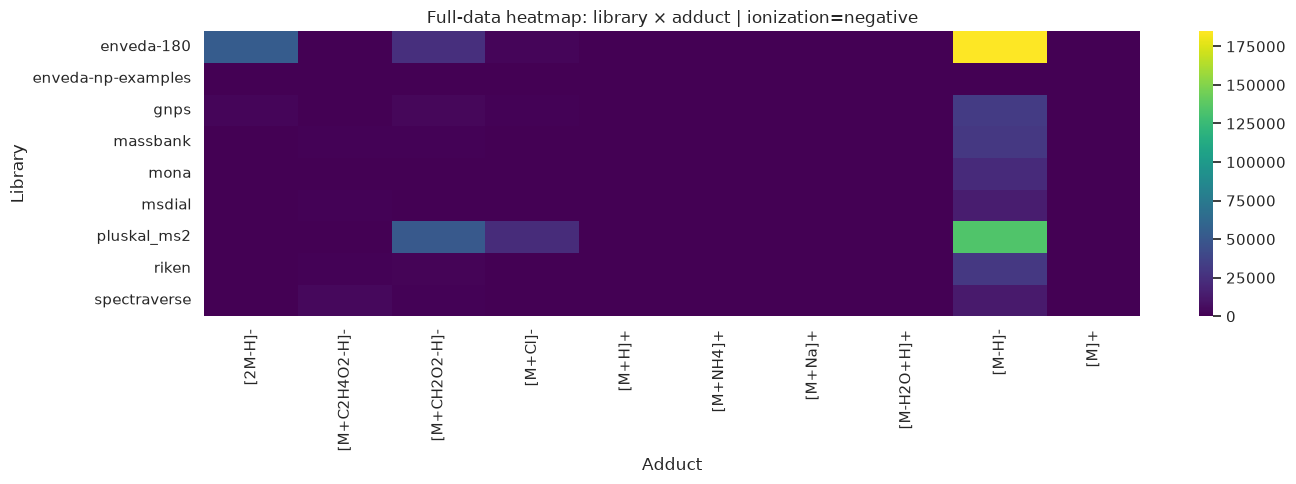

In [16]:
if not jdf.empty:
    lib = jdf.groupby("ingest_lib")["count"].sum().nlargest(12).index
    adduct = jdf.groupby("adduct")["count"].sum().nlargest(15).index
    
    for mode in jdf["ionization_mode"].unique():
        part = jdf[jdf["ionization_mode"].eq(mode) & jdf["ingest_lib"].isin(lib) & jdf["adduct"].isin(adduct)]
        
        if part.empty: 
            continue
        
        matrix = part.pivot_table(index="ingest_lib", columns="adduct", values="count", aggfunc="sum", fill_value=0)
        
        plt.figure(figsize=(14,max(5,.4*len(matrix))))
        sns.heatmap(matrix, cmap="viridis")
        
        plt.title(f"Full-data heatmap: library × adduct | ionization={mode}")
        plt.xlabel("Adduct")
        plt.ylabel("Library")
        
        plt.tight_layout()
        plt.show()

## 13. Scatter plots — numeric relationships

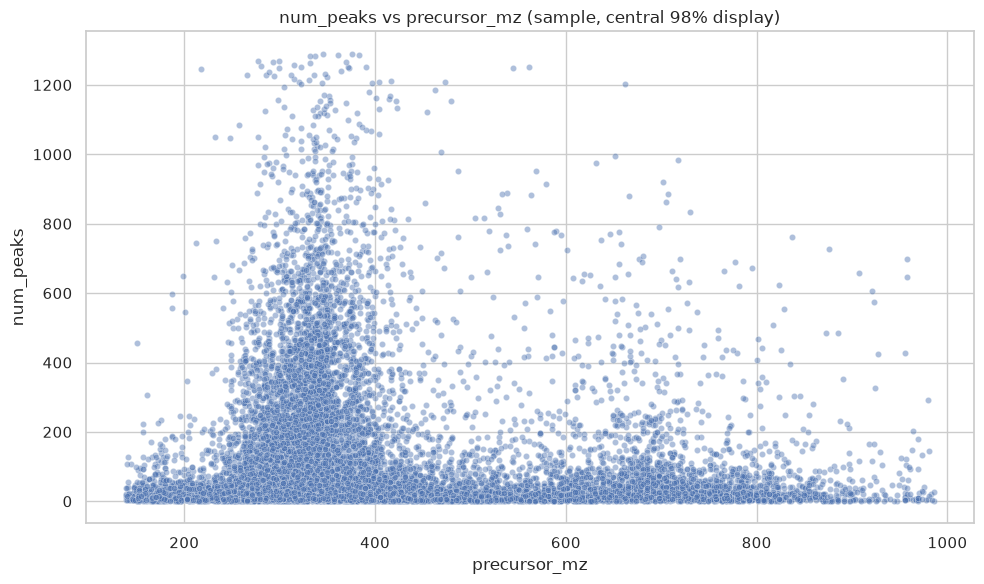

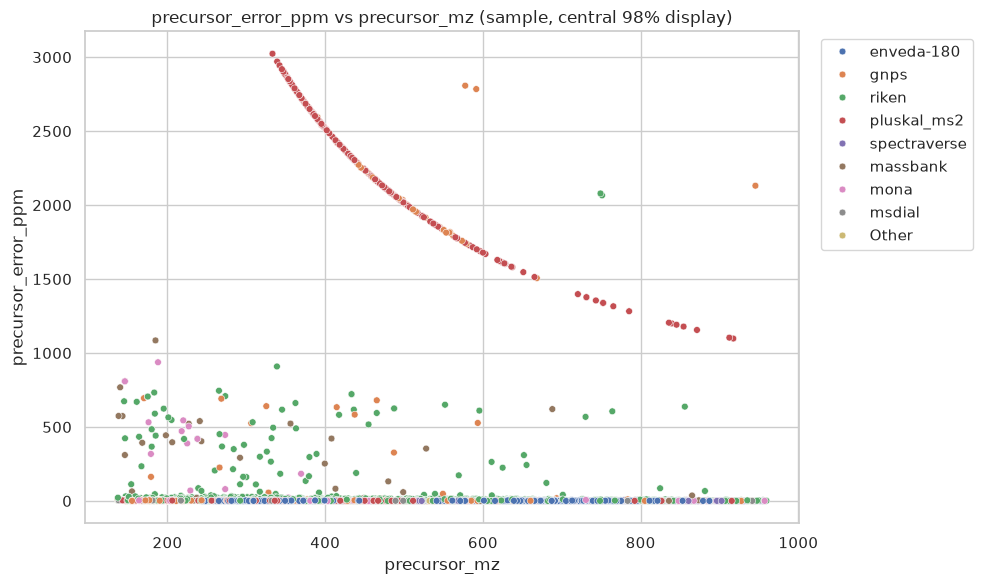

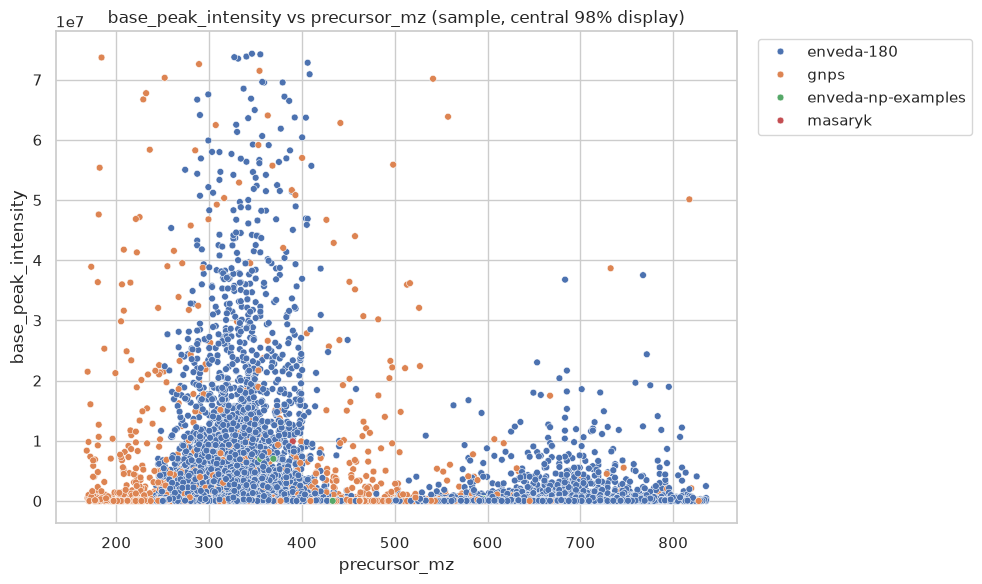

In [17]:
def scat(x, y, hue=None, max_points=15000):
    needed = [x,y] + ([hue] if hue else [])
    
    if not all(c in sample_df.columns for c in needed):
        return
        
    d = sample_df[needed].copy()
    d[x] = safenum(d[x])
    d[y] = safenum(d[y])
    
    
    d = d.replace([np.inf,-np.inf],np.nan).dropna(subset=[x,y])
    if len(d)>max_points: 
        d = d.sample(max_points, random_state=RANDOM_STATE)
    if d.empty: 
        return
    
    
    xl,xh = d[x].quantile([.01,.99])
    yl,yh = d[y].quantile([.01,.99])
    d = d[d[x].between(xl,xh) & d[y].between(yl,yh)]
    
    
    plt.figure(figsize=(10,6))
    
    if hue and hue in d:
        top = d[hue].value_counts().head(8).index
        d[hue] = d[hue].where(d[hue].isin(top),"Other")
        
        
        sns.scatterplot(data=d,x=x,y=y,hue=hue,s=24)
        plt.legend(bbox_to_anchor=(1.02,1),loc="upper left")
        
    else:
        sns.scatterplot(data=d,x=x,y=y,alpha=.45,s=20)
        
    plt.title(f"{y} vs {x} (sample, central 98% display)")
    plt.tight_layout()
    plt.show()

scat("precursor_mz","num_peaks")
scat("precursor_mz","precursor_error_ppm",hue="ingest_lib")
scat("precursor_mz","collision_energy_ev",hue="ionization_mode")
scat("collision_energy_ev","num_peaks",hue="adduct")
scat("precursor_mz","base_peak_intensity",hue="ingest_lib")

## 14. Correlation heatmaps


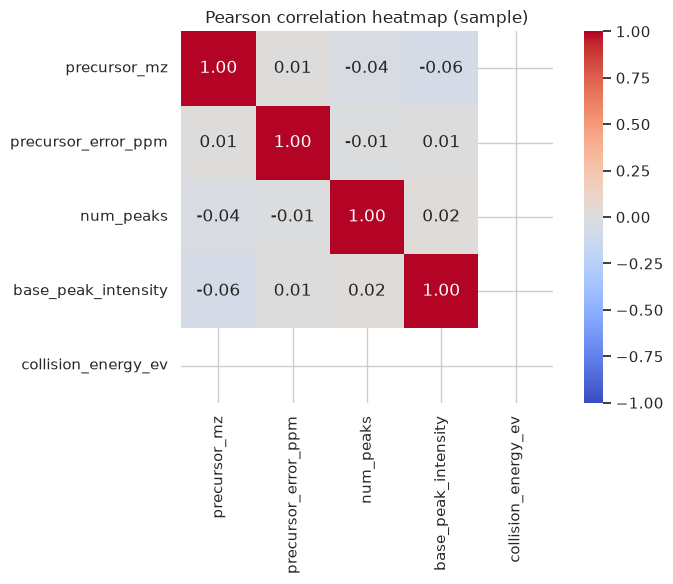

,precursor_mz,precursor_error_ppm,num_peaks,base_peak_intensity,collision_energy_ev
precursor_mz,1.000,0.008,-0.037,-0.065,NaN
precursor_error_ppm,0.008,1.000,-0.009,0.008,NaN
num_peaks,-0.037,-0.009,1.000,0.019,NaN
base_peak_intensity,-0.065,0.008,0.019,1.000,NaN
collision_energy_ev,NaN,NaN,NaN,NaN,NaN


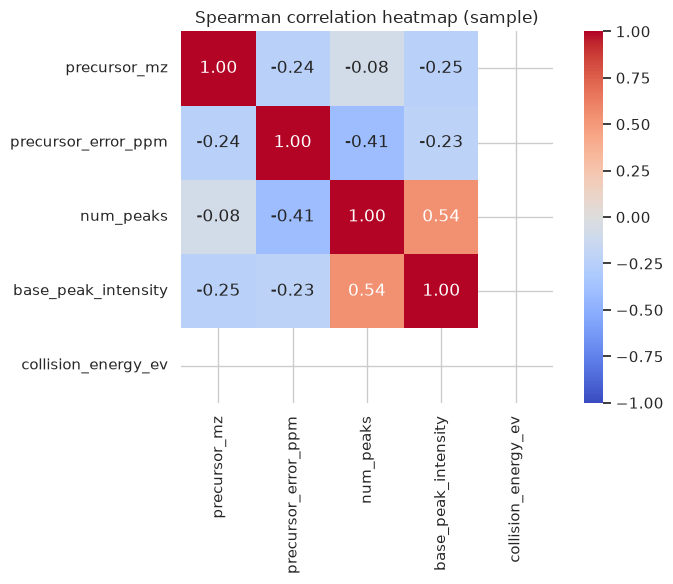

,precursor_mz,precursor_error_ppm,num_peaks,base_peak_intensity,collision_energy_ev
precursor_mz,1.000,-0.242,-0.082,-0.248,NaN
precursor_error_ppm,-0.242,1.000,-0.409,-0.226,NaN
num_peaks,-0.082,-0.409,1.000,0.543,NaN
base_peak_intensity,-0.248,-0.226,0.543,1.000,NaN
collision_energy_ev,NaN,NaN,NaN,NaN,NaN


In [18]:
corcols = [c for c in ["precursor_mz","precursor_error_ppm","num_peaks","base_peak_intensity","collision_energy_ev"] if c in sample_df]
corrdata= sample_df[corcols].apply(safenum).replace([np.inf,-np.inf],np.nan)


if len(corcols)>=2:
    
    for method in ["pearson","spearman"]:
        cor = corrdata.corr(method=method)
        
        plt.figure(figsize=(8,6))
        sns.heatmap(cor, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="coolwarm", square=True)
        
        plt.title(f"{method.title()} correlation heatmap (sample)")
        plt.tight_layout()
        plt.show()
        display(cor.round(3))

## 15. Line charts — ordered trends


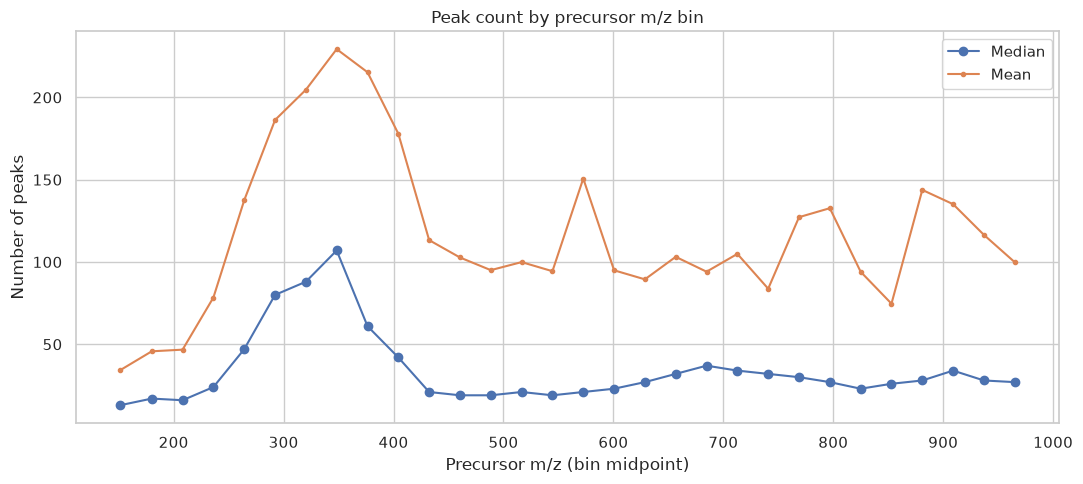

In [19]:
if {"collision_energy_ev","num_peaks"}.issubset(sample_df.columns):
    
    d = sample_df[["collision_energy_ev","num_peaks"]].copy()
    d["collision_energy_ev"] = safenum(d["collision_energy_ev"])
    d["num_peaks"] = safenum(d["num_peaks"])
    d = d.replace([np.inf,-np.inf],np.nan).dropna()
    
    
    if not d.empty:
        l,h = d["collision_energy_ev"].quantile([.01,.99])
        d = d[d["collision_energy_ev"].between(l,h)]
        
        t = d.groupby("collision_energy_ev")["num_peaks"].agg(["count","median","mean"]).reset_index().sort_values("collision_energy_ev")
        t = t[t["count"]>=10]
        
        if not t.empty:
            plt.figure(figsize=(11,5))
            plt.plot(t["collision_energy_ev"],t["median"],marker="o",label="Median peak count")
            plt.plot(t["collision_energy_ev"],t["mean"],marker=".",label="Mean peak count")
            
            plt.title("Peak count by collision energy")
            plt.xlabel("Collision energy (eV)")
            plt.ylabel("Number of peaks")
            
            
            plt.legend()
            plt.tight_layout()
            plt.show()
            
            
            
            
if {"precursor_mz","num_peaks"}.issubset(sample_df.columns):
    d = sample_df[["precursor_mz","num_peaks"]].copy()
    d["precursor_mz"] = safenum(d["precursor_mz"])
    d["num_peaks"] = safenum(d["num_peaks"])
    d = d.replace([np.inf,-np.inf],np.nan).dropna()
    
    if not d.empty:
        l,h = d["precursor_mz"].quantile([.01,.99])
        
        d = d[d["precursor_mz"].between(l,h)].copy()
        d["mz_bin"] = pd.cut(d["precursor_mz"], bins=30)
        
        t = d.groupby("mz_bin",observed=True)["num_peaks"].agg(["count","median","mean"]).reset_index()
        t["mz_midpoint"] = t["mz_bin"].map(lambda z: z.mid)
        
        plt.figure(figsize=(11,5))
        plt.plot(t["mz_midpoint"],t["median"],marker="o",label="Median")
        plt.plot(t["mz_midpoint"],t["mean"],marker=".",label="Mean")
        
        plt.title("Peak count by precursor m/z bin")
        plt.xlabel("Precursor m/z (bin midpoint)")
        plt.ylabel("Number of peaks")
        
        plt.legend()
        plt.tight_layout()
        plt.show()

## 16. Compare distributions across files


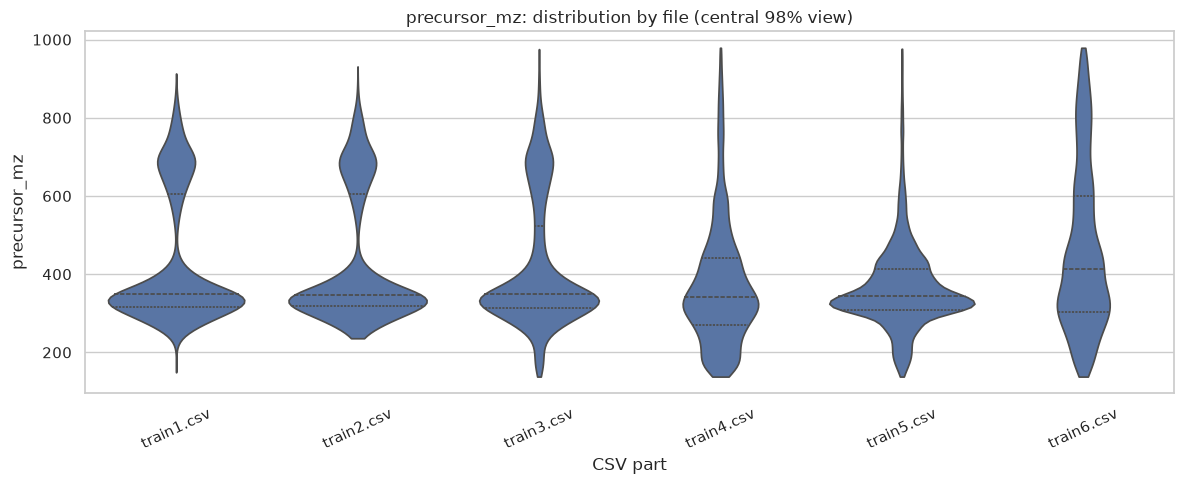

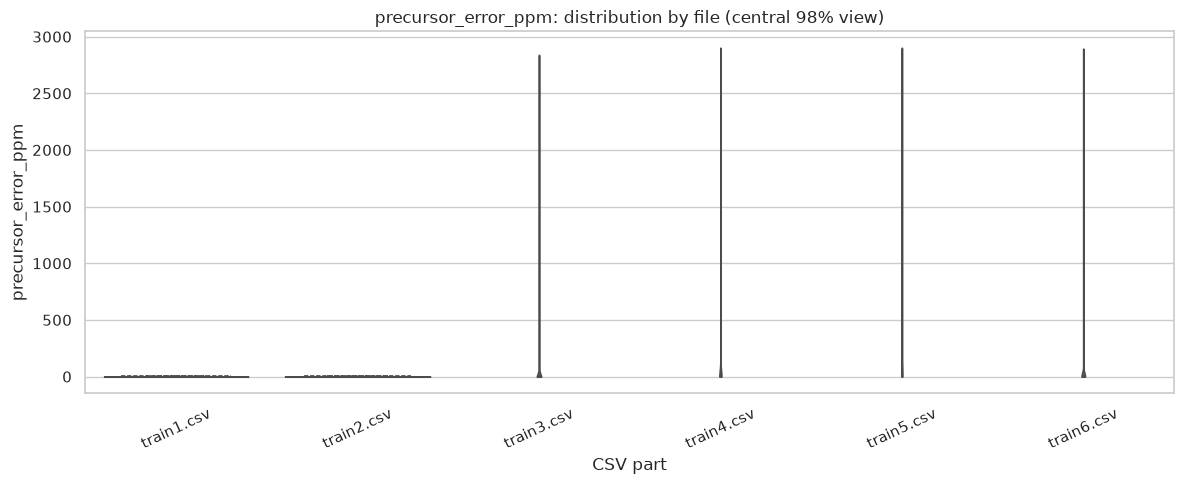

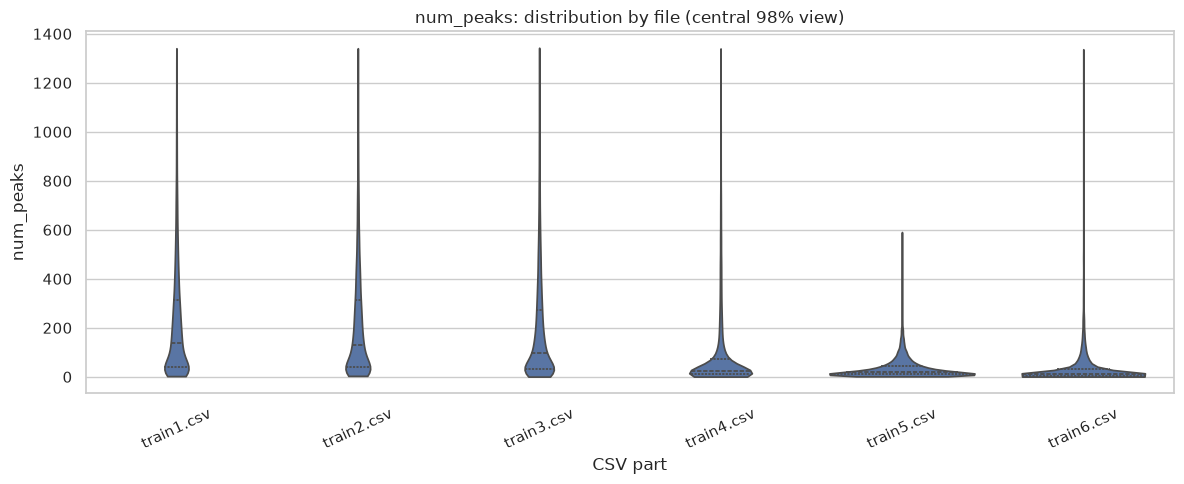

In [20]:
for col in [c for c in ["precursor_mz","precursor_error_ppm","num_peaks","collision_energy_ev"] if c in sample_df]:
    d = sample_df[["source_file",col]].copy()
    
    d[col] = safenum(d[col]); d = d.replace([np.inf,-np.inf],np.nan).dropna()
    if d.empty:
        continue
    
    
    l,h = d[col].quantile([.01,.99]); d = d[d[col].between(l,h)]
    
    
    plt.figure(figsize=(12,5))
    sns.violinplot(data=d,x="source_file",y=col,inner="quartile",cut=0)
    
    plt.title(f"{col}: distribution by file (central 98% view)")
    plt.xlabel("CSV part")
    plt.ylabel(col)
    plt.xticks(rotation=25)
    
    
    plt.tight_layout()
    plt.show()

## 17. Unique molecules and spectra per connectivity ID


Rows scanned: 2,539,608
Unique non-missing connectivity IDs: 275,810
Median spectra per connectivity ID: 6.0


,number_of_IDs
spectra_per_ID,
1,17033
2,16463
3,32969
4,43853
5,18741
6,19057
7,22541
8,32529
9,8803


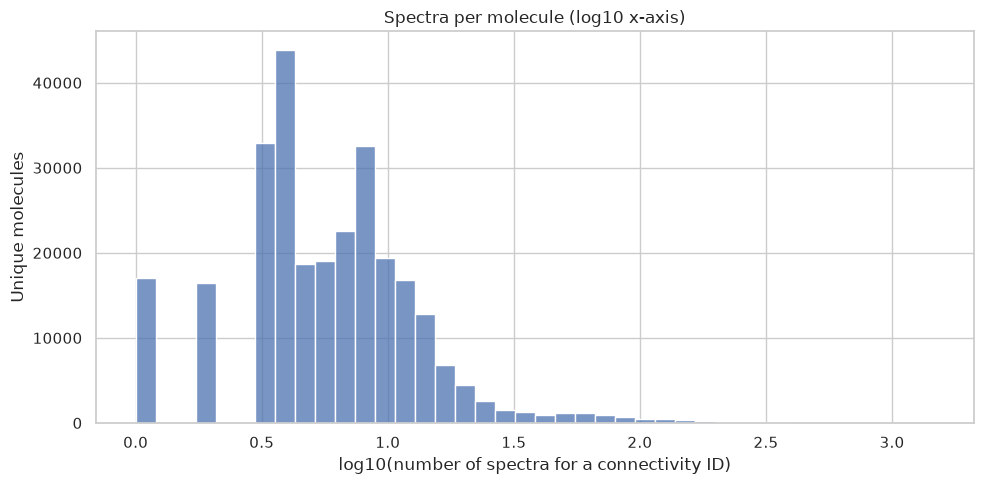

In [23]:

spectrum_counts = Counter()
total_rows = 0
    
    
for path in TRAIN_FILES:
    header = pd.read_csv(path,nrows=0).columns.tolist()
    if "inchikey14" not in header: 
        continue
        
        
    for i in pd.read_csv(path,usecols=["inchikey14"],chunksize=CHUNK_SIZE,low_memory=False):
        ids = i["inchikey14"].dropna().astype(str)
        total_rows += len(i)
        spectrum_counts.update(ids.value_counts().to_dict())
            
            
            
print(f"Rows scanned: {total_rows:,}")
print(f"Unique non-missing connectivity IDs: {len(spectrum_counts):,}")
    
    
    
vals = np.array(list(spectrum_counts.values()))
if len(vals):
    print("Median spectra per connectivity ID:", round(float(np.median(vals)),2))
    display(pd.Series(vals).value_counts().sort_index().head(30).rename_axis("spectra_per_ID").to_frame("number_of_IDs"))
        
        
        
    plt.figure(figsize=(10,5))
    sns.histplot(x=np.log10(vals),bins=40)
    plt.title("Spectra per molecule (log10 x-axis)")
    plt.xlabel("log10(number of spectra for a connectivity ID)")
    plt.ylabel("Unique molecules")
        
    plt.tight_layout()
    plt.show()

## 18. MS/MS array integrity sample


In [24]:
arr = []
ARRAY_CHECK_PER_FILE = 300


for path in TRAIN_FILES:
    header = pd.read_csv(path,nrows=0).columns.tolist()
    req = {"num_peaks","ms2_mzs","ms2_normalized_intensities"}
    if not req.issubset(header):
        continue
    
    cols = [c for c in ["ingest_lib","inchikey14","num_peaks","ms2_mzs","ms2_normalized_intensities"] if c in header]
    cnt = 0
    
    for i in pd.read_csv(path,usecols=cols,chunksize=CHUNK_SIZE,low_memory=False):
        take = min(ARRAY_CHECK_PER_FILE-cnt,len(i))
        if take<=0:
            break
        part = i.sample(take,random_state=RANDOM_STATE) if len(i)>take else i
        
        for r in part.to_dict("records"):
            mzs = safearray(r.get("ms2_mzs"))
            intensity = safearray(r.get("ms2_normalized_intensities"))
            
            
            try: 
                d = float(r.get("num_peaks"))
            except (TypeError,ValueError): 
                d = np.nan
                
                
            arr.append({"file":path.name,"ingest_lib":r.get("ingest_lib"),"inchikey14":r.get("inchikey14"),
                "num_peaks":d,"mzs_length":len(mzs) if mzs is not None else np.nan,
                "intensity_length":len(intensity) if intensity is not None else np.nan,
                "arrays_parseable":mzs is not None and intensity is not None,
                "equal_array_lengths":len(mzs)==len(intensity) if mzs is not None and intensity is not None else False,
                "num_peaks_matches_mzs":d==len(mzs) if mzs is not None and np.isfinite(d) else False})
            
            cnt += 1
            
        if cnt>=ARRAY_CHECK_PER_FILE:
            break
        
        
arrdf = pd.DataFrame(arr)
display(arrdf.head(30))

if not arrdf.empty:
    display(arrdf.groupby("file").agg(sampled_rows=("file","size"),parseable_rate=("arrays_parseable","mean"),equal_array_length_rate=("equal_array_lengths","mean"),num_peaks_match_rate=("num_peaks_matches_mzs","mean")).mul(100).round(2))
    

,file,ingest_lib,inchikey14,num_peaks,mzs_length,intensity_length,arrays_parseable,equal_array_lengths,num_peaks_matches_mzs
0,train1.csv,enveda-180,AKQQZAIXCVIIRA,1051.0,1051,1051,True,True,True
1,train1.csv,drug_plus,POJWUDADGALRAB,200.0,200,200,True,True,True
2,train1.csv,enveda-180,AIIUJKVRKSGSTE,59.0,59,59,True,True,True
3,train1.csv,enveda-180,ABXZIESYEHUPCZ,26.0,26,26,True,True,True
4,train1.csv,enveda-180,AIVHPEJBXFFRQJ,80.0,80,80,True,True,True
5,train1.csv,enveda-180,AEXXLDZFOXPZKI,100.0,100,100,True,True,True
6,train1.csv,drug_plus,OOBHFESNSZDWIU,72.0,72,72,True,True,True
7,train1.csv,enveda-180,AHFCLLKNPXXHOX,261.0,261,261,True,True,True
8,train1.csv,enveda-180,AGIDSGOBDGPMCY,30.0,30,30,True,True,True
9,train1.csv,enveda-180,AGPWEJFZVMDLLE,464.0,464,464,True,True,True


,sampled_rows,parseable_rate,equal_array_length_rate,num_peaks_match_rate
file,,,,
train1.csv,30000,100.0,100.0,100.0
train2.csv,30000,100.0,100.0,100.0
train3.csv,30000,100.0,100.0,100.0
train4.csv,30000,100.0,100.0,100.0
train5.csv,30000,100.0,100.0,100.0
train6.csv,30000,100.0,100.0,100.0


## 19. Data-quality dashboard


In [27]:
q = {"sample_rows":len(sample_df),"files_in_sample":sample_df["source_file"].nunique()}

for c in sample_df:
    q[f"{c}: missing %"] = round(sample_df[c].isna().mean()*100,2)
    
    
for c in ["precursor_mz","precursor_error_ppm","num_peaks","collision_energy_ev"]:
    if c in sample_df:
        s = safenum(sample_df[c]).replace([np.inf,-np.inf],np.nan).dropna()
        if len(s):
            q[f"{c}: min"] = s.min(); q[f"{c}: median"] = s.median(); q[f"{c}: max"] = s.max()
            
            
display(pd.Series(q,name="value").to_frame())

,value
sample_rows,1.015860e+05
files_in_sample,6.000000e+00
ingest_lib: missing %,0.000000e+00
normalized_smiles: missing %,0.000000e+00
inchikey: missing %,0.000000e+00
inchikey14: missing %,0.000000e+00
molecular_formula: missing %,0.000000e+00
ionization_mode: missing %,0.000000e+00
instrument_type: missing %,1.390000e+00
adduct: missing %,0.000000e+00


## 20. Optional export of compact summaries


In [ ]:
EXPORT_SUMMARIES = False
if EXPORT_SUMMARIES:
    summary_dir = Path.cwd() / "eda_summaries"
    summary_dir.mkdir(parents=True,exist_ok=True)
    for col,counter in full_counts.items():
        if counter:
            pd.Series(counter,name="count").rename_axis(col).reset_index().to_csv(summary_dir/f"{col}_counts.csv",index=False)
    if not jdf.empty:
        jdf.to_csv(summary_dir/"library_adduct_ionization_counts.csv",index=False)
    missfile.to_csv(summary_dir/"missingness_by_file.csv")
    print("Saved summaries to",summary_dir.resolve())

Saved summaries to /home/manavtejani/Desktop/Dev/Kaggle/Chemistry/experiments/Notebooks/eda_summaries
